# Dataverse Africa July Challenge
## CHALLENGE: Jumia Jitters
### Theme: E-Commerce Logistics, Seller Risk Profiling, and Review Fraud Detection

#### TASK 1: The Seller Maze (Data Cleaning & Engineering)

In [4]:
# Import Required Libraries
import pandas as pd

In [5]:
# Load the dataset
df = pd.read_csv('jumia_jitters_dataset.csv')

In [6]:
# Inspect Dataset Shape and Columns
print('Shape:', df.shape)
print('Columns:', df.columns.tolist())

Shape: (1000, 16)
Columns: ['Order ID', 'Order Date', 'Dispatch Date', 'Delivery Date', 'Seller ID', 'Product Category', 'Price', 'Quantity', 'Warehouse Zone', 'Customer Rating', 'Review Text', 'Sentiment Score', 'Return Flag', 'Complaint Code', 'Delivery Method', 'Customer Region']


In [7]:
# Display First Few Rows
df.head()

,Order ID,Order Date,Dispatch Date,Delivery Date,Seller ID,Product Category,Price,Quantity,Warehouse Zone,Customer Rating,Review Text,Sentiment Score,Return Flag,Complaint Code,Delivery Method,Customer Region
0,O00000,5/28/2025,5/30/2025,6/6/2025,S033,Fashion,193.52,1.0,Kano,4.0,Packaging could be better but the item works f...,0.458333,No,No Complaint,Express,North Central
1,O00001,6/24/2025,6/26/2025,7/3/2025,S018,Groceries,86.45,3.0,Lagos,3.0,Packaging could be better but the item works f...,0.458333,No,No Complaint,Standard,Volta
2,O00002,NaN,6/6/2025,6/7/2025,S036,Home & Living,80.00,3.0,Kumasi,4.0,"It's okay, not too bad but not amazing either.",-0.166667,No,No Complaint,Standard,Ashanti
3,O00003,NaN,6/24/2025,6/28/2025,S001,Health,469.89,2.0,Kano,4.0,Excellent quality and affordable price. Highly...,0.580000,No,No Complaint,Pickup,North Central
4,O00004,NaN,4/14/2025,4/22/2025,S024,Groceries,309.71,1.0,Accra,3.0,Item arrived in perfect condition and works well.,1.000000,No,No Complaint,Standard,Greater Accra


In [ ]:
# Data Cleaning and Feature Engineering Function

def clean_data(df):
    # Clean inconsistent entries in Seller ID, Product Category, and Warehouse Zone columns
    df['Seller ID'] = df['Seller ID'].str.strip().str.title()
    df['Product Category'] = df['Product Category'].str.strip().str.title()
    df['Warehouse Zone'] = df['Warehouse Zone'].str.strip().str.title()

    # Calculate Delivery Delay as the difference between Delivery Date and Dispatch Date
    df['Delivery Date'] = pd.to_datetime(df['Delivery Date'], errors='coerce')
    df['Dispatch Date'] = pd.to_datetime(df['Dispatch Date'], errors='coerce')
    df['Delivery Delay'] = (df['Delivery Date'] - df['Dispatch Date']).dt.days

    # Engineer new features: Return Rate, Average Rating, Complaint Rate per seller
    # Calculate Return Rate per seller
    return_rate = df.groupby('Seller ID')['Return Flag'].apply(lambda x: (x == 'Yes').mean()).reset_index()
    return_rate.rename(columns={'Return Flag': 'Return Rate'}, inplace=True)

    # Calculate Average Rating per seller
    average_rating = df.groupby('Seller ID')['Customer Rating'].mean().reset_index()
    average_rating.rename(columns={'Customer Rating': 'Average Rating'}, inplace=True)

    # Calculate Complaint Rate per seller
    complaint_rate = df.groupby('Seller ID')['Complaint Code'].apply(lambda x: (x != 'No Complaint').mean()).reset_index()
    complaint_rate.rename(columns={'Complaint Code': 'Complaint Rate'}, inplace=True)

    # Merge the new features back into the DataFrame
    df = df.merge(return_rate, on='Seller ID', how='left')
    df = df.merge(average_rating, on='Seller ID', how='left')
    df = df.merge(complaint_rate, on='Seller ID', how='left')

    # Fix duplicate and suspicious flags, engineer features
    # Correcting the 'Duplicate Flag' and 'Suspicious Flag' columns
    df['Duplicate Flag'] = df['Quantity'] > 1
    df['Suspicious Flag'] = (df['Customer Rating'] < 2) | (df['Delivery Delay'] > 10)

    # Engineering new features without removing existing columns
    df['Total Price'] = df['Price'] * df['Quantity']
    df['Delivery Efficiency'] = df['Delivery Delay'] / df['Quantity']

    # Ensuring all columns are retained
    df = df.copy()
    
    # Calculate Seller Risk Score using weighted formula
    df['Seller Risk Score'] = (
        0.4 * df['Delivery Delay'] + 
        0.3 * df['Return Rate'] + 
        0.3 * df['Complaint Rate']
    )
    return df

df_clean = clean_data(df.copy())
df_clean.head()

,Order ID,Order Date,Dispatch Date,Delivery Date,Seller ID,Product Category,Price,Quantity,Warehouse Zone,Customer Rating,...,Customer Region,Delivery Delay,Return Rate,Average Rating,Complaint Rate,Duplicate Flag,Suspicious Flag,Total Price,Delivery Efficiency,Seller Risk Score
0,O00000,5/28/2025,2025-05-30,2025-06-06,S033,Fashion,193.52,1.0,Kano,4.0,...,North Central,7.0,0.041667,3.166667,0.083333,False,False,193.52,7.000000,2.837500
1,O00001,6/24/2025,2025-06-26,2025-07-03,S018,Groceries,86.45,3.0,Lagos,3.0,...,Volta,7.0,0.050000,3.200000,0.050000,True,False,259.35,2.333333,2.830000
2,O00002,NaN,2025-06-06,2025-06-07,S036,Home & Living,80.00,3.0,Kumasi,4.0,...,Ashanti,1.0,0.117647,3.705882,0.058824,True,False,240.00,0.333333,0.452941
3,O00003,NaN,2025-06-24,2025-06-28,S001,Health,469.89,2.0,Kano,4.0,...,North Central,4.0,0.000000,3.277778,0.000000,True,False,939.78,2.000000,1.600000
4,O00004,NaN,2025-04-14,2025-04-22,S024,Groceries,309.71,1.0,Accra,3.0,...,Greater Accra,8.0,0.052632,3.526316,0.052632,False,False,309.71,8.000000,3.231579


In [ ]:

def clean_data(df_clean):
    # Fill missing values using column-specific strategies
    df_clean['Order Date'] = df_clean['Order Date'].fillna(method='ffill')  # Forward fill for dates
    df_clean['Customer Rating'] = df_clean['Customer Rating'].fillna(df_clean['Customer Rating'].mean())  # Mean for numerical ratings
    df_clean['Review Text'] = df_clean['Review Text'].fillna('No Review')  # Default text for missing reviews

    # Drop rows where both Dispatch Date and Delivery Date are missing
    df_clean = df_clean.dropna(subset=['Dispatch Date', 'Delivery Date'], how='all')

    # Forward fill missing values for Dispatch Date and Delivery Date
    df_clean[['Dispatch Date', 'Delivery Date']] = df_clean[['Dispatch Date', 'Delivery Date']].fillna(method='ffill')
    
    # Drop rows where Quantity is missing
    df_clean = df_clean.dropna(subset=['Quantity'])
    # Fill missing Price using the mean price of the same Product Category
    df_clean['Price'] = df_clean.groupby('Product Category')['Price'].transform(lambda x: x.fillna(x.mean()))
    # Drop rows where Product Category is missing
    df_clean = df_clean.dropna(subset=['Product Category'])
    # Drop rows where Warehouse Zone is missing
    df_clean = df_clean.dropna(subset=['Warehouse Zone'])
    # Drop rows where Complaint Code is missing
    df_clean = df_clean.dropna(subset=['Complaint Code'])
    # Drop rows where Total Price is missing
    df_clean = df_clean.dropna(subset=['Total Price'])
    # Drop rows where Delivery Efficiency is missing
    df_clean = df_clean.dropna(subset=['Delivery Efficiency'])
    # Drop rows where Sentiment Score is missing
    df_clean = df_clean.dropna(subset=['Sentiment Score'])
    return df_clean

df_clean_1 = clean_data(df_clean.copy())
df_clean_1.head()

C:\Users\hp\AppData\Local\Temp\ipykernel_18988\9802640.py:6: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df_clean['Order Date'] = df_clean['Order Date'].fillna(method='ffill')  # Forward fill for dates
C:\Users\hp\AppData\Local\Temp\ipykernel_18988\9802640.py:12: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df_clean[['Dispatch Date', 'Delivery Date']] = df_clean[['Dispatch Date', 'Delivery Date']].fillna(method='ffill')


,Order ID,Order Date,Dispatch Date,Delivery Date,Seller ID,Product Category,Price,Quantity,Warehouse Zone,Customer Rating,...,Customer Region,Delivery Delay,Return Rate,Average Rating,Complaint Rate,Duplicate Flag,Suspicious Flag,Total Price,Delivery Efficiency,Seller Risk Score
0,O00000,5/28/2025,2025-05-30,2025-06-06,S033,Fashion,193.52,1.0,Kano,4.0,...,North Central,7.0,0.041667,3.166667,0.083333,False,False,193.52,7.000000,2.837500
1,O00001,6/24/2025,2025-06-26,2025-07-03,S018,Groceries,86.45,3.0,Lagos,3.0,...,Volta,7.0,0.050000,3.200000,0.050000,True,False,259.35,2.333333,2.830000
2,O00002,6/24/2025,2025-06-06,2025-06-07,S036,Home & Living,80.00,3.0,Kumasi,4.0,...,Ashanti,1.0,0.117647,3.705882,0.058824,True,False,240.00,0.333333,0.452941
3,O00003,6/24/2025,2025-06-24,2025-06-28,S001,Health,469.89,2.0,Kano,4.0,...,North Central,4.0,0.000000,3.277778,0.000000,True,False,939.78,2.000000,1.600000
4,O00004,6/24/2025,2025-04-14,2025-04-22,S024,Groceries,309.71,1.0,Accra,3.0,...,Greater Accra,8.0,0.052632,3.526316,0.052632,False,False,309.71,8.000000,3.231579


In [10]:
# Check for missing values in each column
missing_counts = df.isnull().sum()
print(missing_counts)

# Show columns with missing values only
missing_counts[missing_counts > 0]

Order ID             0
Order Date           7
Dispatch Date        4
Delivery Date        2
Seller ID            0
Product Category    11
Price               26
Quantity             9
Warehouse Zone      19
Customer Rating      3
Review Text         33
Sentiment Score      6
Return Flag          0
Complaint Code      12
Delivery Method      0
Customer Region      0
dtype: int64


Order Date           7
Dispatch Date        4
Delivery Date        2
Product Category    11
Price               26
Quantity             9
Warehouse Zone      19
Customer Rating      3
Review Text         33
Sentiment Score      6
Complaint Code      12
dtype: int64

In [11]:
# Handle missing values
# Fill missing numerical columns with their mean
num_cols = df.select_dtypes(include=['float64', 'int64']).columns
for col in num_cols:
    df[col] = df[col].fillna(df[col].mean())

# Fill missing categorical columns with their mode
cat_cols = df.select_dtypes(include=['object']).columns
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

# Check again for missing values
df.isnull().sum()

Order ID            0
Order Date          0
Dispatch Date       0
Delivery Date       0
Seller ID           0
Product Category    0
Price               0
Quantity            0
Warehouse Zone      0
Customer Rating     0
Review Text         0
Sentiment Score     0
Return Flag         0
Complaint Code      0
Delivery Method     0
Customer Region     0
dtype: int64

## Task 2: Pattern Surveillance (Analytics & Visualization)
Identify top & bottom sellers by fulfillment reliability.

In [31]:
# Calculate fulfillment reliability as 1 - average delivery delay per seller
seller_reliability = df_clean_1.groupby('Seller ID')['Delivery Delay'].mean().reset_index()
seller_reliability['Fulfillment Reliability'] = 1 - (seller_reliability['Delivery Delay'] / seller_reliability['Delivery Delay'].max())

# Top 5 sellers by reliability
print('Top 5 Sellers by Fulfillment Reliability:')
print(seller_reliability.sort_values('Fulfillment Reliability', ascending=False).head())

# Bottom 5 sellers by reliability
print('Bottom 5 Sellers by Fulfillment Reliability:')
print(seller_reliability.sort_values('Fulfillment Reliability').head())

Top 5 Sellers by Fulfillment Reliability:
   Seller ID  Delivery Delay  Fulfillment Reliability
3       S004        2.846154                 0.525641
17      S018        2.947368                 0.508772
39      S040        3.000000                 0.500000
33      S034        3.062500                 0.489583
38      S039        3.461538                 0.423077
Bottom 5 Sellers by Fulfillment Reliability:
   Seller ID  Delivery Delay  Fulfillment Reliability
9       S010        6.000000                 0.000000
18      S019        5.700000                 0.050000
5       S006        5.611111                 0.064815
6       S007        5.600000                 0.066667
4       S005        5.222222                 0.129630


In [32]:
# Fix KeyError: sort by the correct column name
complaints_by_category = df_clean_1.groupby('Product Category')['Complaint Code'].apply(lambda x: (x != 'No Complaint').sum()).reset_index(name='Complaint Count')
complaints_by_category = complaints_by_category.sort_values('Complaint Count', ascending=False)
print('Product categories with highest complaints:')
print(complaints_by_category.head())

Product categories with highest complaints:
  Product Category  Complaint Count
0      Electronics                7
4           Health                3
8             Toys                3
3        Groceries                2
5    Home & Living                2


In [33]:
# Regions with the longest average delivery delays
region_delays = df_clean_1.groupby('Warehouse Zone')['Delivery Delay'].mean().reset_index()
region_delays = region_delays.sort_values('Delivery Delay', ascending=False)
print('Regions with the longest average delivery delays:')
print(region_delays.head())

Regions with the longest average delivery delays:
  Warehouse Zone  Delivery Delay
3         Kumasi        4.660793
2          Kumas        4.600000
1           Kano        4.529915
5          Lagos        4.497758
0          Accra        4.313636


-> Identify review texts that appear more than once and prints the top 10 most repeated review texts with their counts.

In [34]:
# Spot review fraud using repetitive text patterns
from collections import Counter

# Find most common review texts
review_counts = Counter(df_clean_1['Review Text'])
repetitive_reviews = [text for text, count in review_counts.items() if count > 1]

print('Suspicious repetitive review texts:')
for text in repetitive_reviews[:10]:  # Show top 10
    print(f'Text: {text} | Count: {review_counts[text]}')

Suspicious repetitive review texts:
Text: Packaging could be better but the item works fine. | Count: 56
Text: It's okay, not too bad but not amazing either. | Count: 67
Text: Excellent quality and affordable price. Highly recommend. | Count: 65
Text: Item arrived in perfect condition and works well. | Count: 48
Text: Fast delivery, item exactly as described. Very satisfied! | Count: 62
Text: Low quality. Would not recommend at all. | Count: 59
Text: Arrived late and the item looks used. | Count: 54
Text: Met my expectations, nothing more. | Count: 63
Text: Just received it, will see how it performs over time. | Count: 54
Text: Absolutely love this product, great value for money. | Count: 55


In [35]:
# Order repetitive review texts from most used to least
repetitive_review_counts = [(text, count) for text, count in review_counts.items() if count > 1]
repetitive_review_counts.sort(key=lambda x: x[1], reverse=True)

print('Repetitive review texts ordered from most to least used:')
for text, count in repetitive_review_counts[:10]:  # Show top 10
    print(f'Text: {text} | Count: {count}')

Repetitive review texts ordered from most to least used:
Text: Delivery was average, product as expected. | Count: 83
Text: It's okay, not too bad but not amazing either. | Count: 67
Text: Excellent quality and affordable price. Highly recommend. | Count: 65
Text: Fake product and horrible packaging. | Count: 65
Text: Met my expectations, nothing more. | Count: 63
Text: Fast delivery, item exactly as described. Very satisfied! | Count: 62
Text: Low quality. Would not recommend at all. | Count: 59
Text: Terrible experience. Product was broken. | Count: 57
Text: Packaging could be better but the item works fine. | Count: 56
Text: Absolutely love this product, great value for money. | Count: 55


In [36]:
# Check if 'Return Rate' column exists and inspect its values
print('Return Rate column in df_clean_1:', 'Return Rate' in df_clean_1.columns)
if 'Return Rate' in df_clean_1.columns:
    print(df_clean_1['Return Rate'].describe())
    print(df_clean_1[['Seller ID', 'Return Rate']].head())
else:
    print('Return Rate column not found in df_clean_1.')

Return Rate column in df_clean_1: True
count    912.000000
mean       0.023555
std        0.033480
min        0.000000
25%        0.000000
50%        0.000000
75%        0.043478
max        0.133333
Name: Return Rate, dtype: float64
  Seller ID  Return Rate
0      S033     0.041667
1      S018     0.050000
2      S036     0.117647
3      S001     0.000000
4      S024     0.052632


In [37]:
# Find sellers with only 5-star ratings
seller_ratings = df_clean_1.groupby('Seller ID')['Customer Rating'].unique()
only_5_star_sellers = seller_ratings[seller_ratings.apply(lambda x: set(x) == {5.0})].index

# Calculate return rates for sellers with only 5-star ratings
return_rate_5star = df_clean_1[df_clean_1['Seller ID'].isin(only_5_star_sellers)].groupby('Seller ID')['Return Flag'].apply(lambda x: (x == 'Yes').mean())

# Calculate return rates for sellers without only 5-star ratings
other_sellers = seller_ratings[seller_ratings.apply(lambda x: set(x) != {5.0})].index
return_rate_others = df_clean_1[df_clean_1['Seller ID'].isin(other_sellers)].groupby('Seller ID')['Return Flag'].apply(lambda x: (x == 'Yes').mean())

# Get threshold for high return rate among other sellers (top 25%)
threshold = return_rate_others.quantile(0.75)

# Flag suspicious sellers: only 5-star ratings and return rate above threshold
suspicious = return_rate_5star[return_rate_5star > threshold]

print(f'Suspicious sellers with only 5-star ratings and high return rate (threshold: {threshold:.2f}):')
print(suspicious)

Suspicious sellers with only 5-star ratings and high return rate (threshold: 0.05):
Series([], Name: Return Flag, dtype: object)


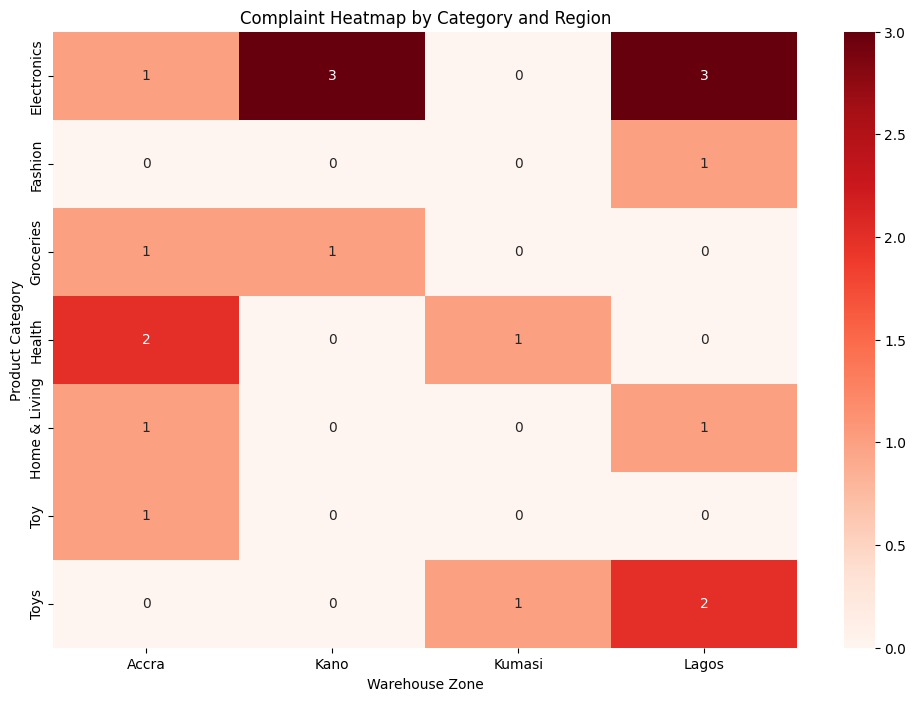

In [38]:
# Create a Complaint Heatmap by category and region
import seaborn as sns
import matplotlib.pyplot as plt

# Prepare data: count complaints by category and region
heatmap_data = df_clean_1[df_clean_1['Complaint Code'] != 'No Complaint'].groupby(['Product Category', 'Warehouse Zone']).size().unstack(fill_value=0)

plt.figure(figsize=(12, 8))
sns.heatmap(heatmap_data, annot=True, fmt='d', cmap='Reds')
plt.title('Complaint Heatmap by Category and Region')
plt.ylabel('Product Category')
plt.xlabel('Warehouse Zone')
plt.show()

In [39]:
# Confirm seaborn and matplotlib installation
#import sys
#print(sys.executable)

#!{sys.executable} -m pip install seaborn matplotlib

#import seaborn as sns
#import matplotlib.pyplot as plt
#print("Seaborn and matplotlib imported successfully!")

In [40]:
# Install scipy in the active notebook kernel
# !pip install scipy

# Statistical validation: Does Delivery Method affect Customer Rating?      
from scipy.stats import f_oneway
delivery_methods = df_clean_1['Delivery Method'].unique()
groups = [df_clean_1[df_clean_1['Delivery Method'] == method]['Customer Rating'].dropna() for method in delivery_methods]
anova_result = f_oneway(*groups)
print('ANOVA F-statistic:', anova_result.statistic)
print('ANOVA p-value:', anova_result.pvalue)
if anova_result.pvalue < 0.05:
    print('Result: There is a statistically significant difference in customer ratings between delivery methods.')
else:
    print('Result: No statistically significant difference in customer ratings between delivery methods.')

ANOVA F-statistic: 0.8320714878944817
ANOVA p-value: 0.4354781035665165
Result: No statistically significant difference in customer ratings between delivery methods.


## Task 3: Prediction & Risk Modeling

In [41]:
# Install imblearn for SMOTE in the active notebook kernel
# !pip install imblearn

# Handling Data Imbalance for Prediction & Risk Modeling
from collections import Counter
from imblearn.over_sampling import SMOTE
import numpy as np
target = 'Return Flag'  # Specify the target column for classification
print('Class distribution:', Counter(df_clean_1[target]))
if len(set(df_clean_1[target])) == 2:
    # Encode target if not numeric
    y = df_clean_1[target].map({'Yes': 1, 'No': 0}) if df_clean_1[target].dtype == 'object' else df_clean_1[target]
    X = df_clean_1.drop(columns=[target])
    # Select only numeric features
    X_numeric = X.select_dtypes(include=np.number)
    smote = SMOTE(random_state=42)
    X_resampled, y_resampled = smote.fit_resample(X_numeric, y)
    print('Resampled class distribution:', Counter(y_resampled))
else:
    print('SMOTE is for binary classification. For multi-class, use SMOTE for multi-class or other techniques.')

Class distribution: Counter({'No': 889, 'Yes': 23})
Resampled class distribution: Counter({0: 889, 1: 889})


# Build a classification model

In [42]:
# Apply SMOTE to training set and model on balanced data (no NLP)
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.preprocessing import LabelEncoder
import numpy as np
target = 'Return Flag'
# Select relevant features (no Review Text)
features = ['Seller ID', 'Product Category', 'Price', 'Delivery Delay', 'Complaint Code']
X = df_clean_1[features].copy()
# Encode categorical features
for col in ['Seller ID', 'Product Category', 'Complaint Code']:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col].astype(str))
# Encode target
y = df_clean_1[target].map({'Yes': 1, 'No': 0}) if df_clean_1[target].dtype == 'object' else df_clean_1[target]
# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
# Apply SMOTE to training set only
smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)
from collections import Counter
print('Resampled class distribution (no NLP):', Counter(y_train_bal))
# Train model on balanced data
clf = RandomForestClassifier(random_state=42)
clf.fit(X_train_bal, y_train_bal)
# Predict on original test set
y_pred = clf.predict(X_test)
# Evaluate
print('Accuracy with SMOTE (no NLP):', accuracy_score(y_test, y_pred))
print('Confusion Matrix:\n', confusion_matrix(y_test, y_pred))
print('Classification Report:\n', classification_report(y_test, y_pred))

Resampled class distribution (no NLP): Counter({0: 711, 1: 711})
Accuracy with SMOTE (no NLP): 0.9836065573770492
Confusion Matrix:
 [[176   2]
 [  1   4]]
Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.99      0.99       178
           1       0.67      0.80      0.73         5

    accuracy                           0.98       183
   macro avg       0.83      0.89      0.86       183
weighted avg       0.99      0.98      0.98       183

Accuracy with SMOTE (no NLP): 0.9836065573770492
Confusion Matrix:
 [[176   2]
 [  1   4]]
Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.99      0.99       178
           1       0.67      0.80      0.73         5

    accuracy                           0.98       183
   macro avg       0.83      0.89      0.86       183
weighted avg       0.99      0.98      0.98       183



# Optional: Use NLP to vectorize Review Text and test impact on return predictions

In [43]:
# Apply SMOTE to training set and model on balanced data (with NLP)
from imblearn.over_sampling import SMOTE
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.preprocessing import LabelEncoder
import numpy as np
target = 'Return Flag'
# Select relevant features including Review Text
features = ['Seller ID', 'Product Category', 'Price', 'Delivery Delay', 'Complaint Code', 'Review Text']
X = df_clean_1[features].copy()
# Encode categorical features except Review Text
for col in ['Seller ID', 'Product Category', 'Complaint Code']:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col].astype(str))
# Vectorize Review Text
tfidf = TfidfVectorizer(max_features=100)
review_tfidf = tfidf.fit_transform(X['Review Text'].astype(str)).toarray()
# Drop original Review Text and concatenate TF-IDF features
X = X.drop(columns=['Review Text'])
import pandas as pd
tfidf_df = pd.DataFrame(review_tfidf, columns=[f'tfidf_{i}' for i in range(review_tfidf.shape[1])])
X = pd.concat([X.reset_index(drop=True), tfidf_df], axis=1)
# Encode target
y = df_clean_1[target].map({'Yes': 1, 'No': 0}) if df_clean_1[target].dtype == 'object' else df_clean_1[target]
# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
# Apply SMOTE to training set only
smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)
from collections import Counter
print('Resampled class distribution (with NLP):', Counter(y_train_bal))
# Train model on balanced data
clf = RandomForestClassifier(random_state=42)
clf.fit(X_train_bal, y_train_bal)
# Predict on original test set
y_pred = clf.predict(X_test)
# Evaluate
print('Accuracy with SMOTE (with NLP):', accuracy_score(y_test, y_pred))
print('Confusion Matrix:\n', confusion_matrix(y_test, y_pred))
print('Classification Report:\n', classification_report(y_test, y_pred))

Resampled class distribution (with NLP): Counter({0: 711, 1: 711})
Accuracy with SMOTE (with NLP): 0.9726775956284153
Confusion Matrix:
 [[178   0]
 [  5   0]]
Classification Report:
               precision    recall  f1-score   support

           0       0.97      1.00      0.99       178
           1       0.00      0.00      0.00         5

    accuracy                           0.97       183
   macro avg       0.49      0.50      0.49       183
weighted avg       0.95      0.97      0.96       183

Accuracy with SMOTE (with NLP): 0.9726775956284153
Confusion Matrix:
 [[178   0]
 [  5   0]]
Classification Report:
               precision    recall  f1-score   support

           0       0.97      1.00      0.99       178
           1       0.00      0.00      0.00         5

    accuracy                           0.97       183
   macro avg       0.49      0.50      0.49       183
weighted avg       0.95      0.97      0.96       183



c:\Users\hp\anaconda3\envs\jupyter_r_env\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\hp\anaconda3\envs\jupyter_r_env\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\hp\anaconda3\envs\jupyter_r_env\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(r

Classification Report:

Precision, recall, and f1-score for class 1 (Return) are all 0.00.
The model fails to identify any returns in the test set, even after balancing and using NLP features.
Why?

The test set is highly imbalanced (very few returns).

What to do next?

Try more advanced feature engineering (sentiment analysis, aggregations).
Use more sensitive metrics (recall, f1-score for minority class).
Consider threshold tuning, cost-sensitive learning, or ensemble methods.

## TASK 4: Strategy & Resolution

#### Enhanced Recommendation Approach

In [51]:
# Display top 5 sellers to suspend with metrics
print("Top 5 Sellers to Suspend (with metrics):")
print(top5_suspend[['Seller ID', 'Last Month Return Rate', 'Return Rate Increase']])

Top 5 Sellers to Suspend (with metrics):
  Seller ID  Last Month Return Rate  Return Rate Increase
0      S039                0.400000              0.400000
1      S004                0.166667              0.166667
2      S018                0.166667              0.166667
3      S014                0.142857              0.142857
4      S036                0.142857              0.142857


In [52]:
# Recommend product categories to blacklist or regulate based on complaint counts
# Use complaints_by_category from CELL INDEX 11

# Set a threshold for high complaints (e.g., top 3 categories)
top_n = 3
blacklist_candidates = complaints_by_category.head(top_n)

print("Recommended product categories to blacklist or regulate (highest complaints):")
print(blacklist_candidates[['Product Category', 'Complaint Count']])

Recommended product categories to blacklist or regulate (highest complaints):
  Product Category  Complaint Count
0      Electronics                7
4           Health                3
8             Toys                3


### Actionable Strategies to Reduce Delivery Delays
1. **Prioritize High-Delay Regions:** Focus operational improvements on warehouse zones and regions identified with the longest average delivery delays.
2. **Optimize Seller Dispatch Times:** Work with sellers to reduce the time between order placement and dispatch, possibly by setting stricter SLAs or providing incentives for fast dispatch.
3. **Improve Logistics Partnerships:** Collaborate with delivery partners to streamline last-mile delivery, especially in regions with frequent delays.
4. **Monitor and Flag Chronic Offenders:** Use analytics to continuously monitor sellers and products with repeated delivery delays, and provide targeted feedback or penalties.
5. **Enhance Inventory Management:** Ensure popular products are stocked closer to high-demand regions to minimize transit time.
6. **Leverage Predictive Analytics:** Use historical data to forecast potential delays and proactively reroute or expedite shipments.

### Customer Trust Policy
- **Transparent Communication:** We commit to providing clear, timely updates on order status, delivery timelines, and any issues that may arise.
- **Fair Resolution:** All customer complaints and return requests are handled promptly and fairly, ensuring customer satisfaction and trust.
- **Continuous Improvement:** We regularly review feedback and performance data to enhance our service quality and protect customer interests.

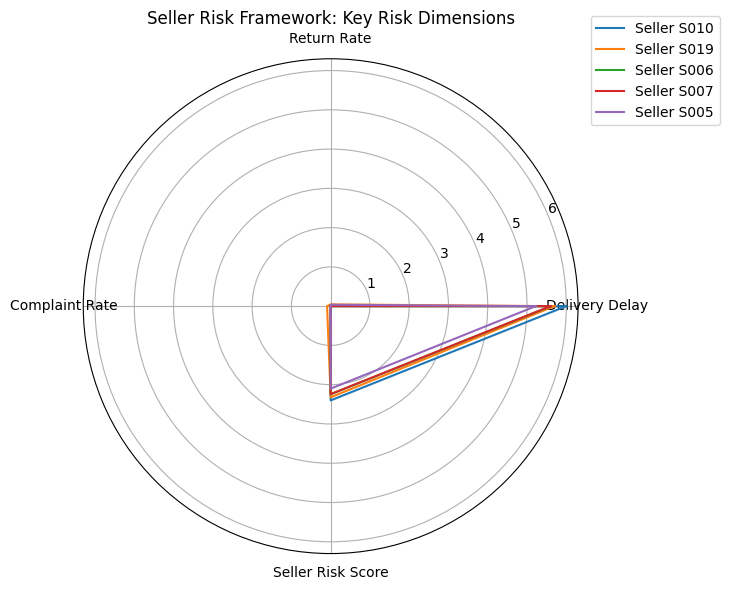

Framework Dimensions:
- Delivery Delay: Average days delayed per seller
- Return Rate: Proportion of orders returned
- Complaint Rate: Proportion of orders with complaints
- Seller Risk Score: Weighted composite risk metric


In [ ]:
# Seller Risk Framework Visual (Slide for Board Presentation)

# Example: Radar chart of key risk dimensions per seller (use top 5 risky sellers)
risk_metrics = ['Delivery Delay', 'Return Rate', 'Complaint Rate', 'Seller Risk Score']
# Select only numeric columns for aggregation
numeric_cols = risk_metrics
top_risk_sellers = (
    df_clean_1.groupby('Seller ID')[numeric_cols]
    .mean()
    .sort_values('Seller Risk Score', ascending=False)
    .head(5)
)

labels = risk_metrics
num_vars = len(labels)

angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
angles += angles[:1]

plt.figure(figsize=(8, 6))
for idx, (seller, row) in enumerate(top_risk_sellers.iterrows()):
    values = [row[m] for m in risk_metrics]
    values += values[:1]
    plt.polar(angles, values, label=f'Seller {seller}')

plt.xticks(angles[:-1], labels)
plt.title('Seller Risk Framework: Key Risk Dimensions')
plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
plt.tight_layout()
plt.show()



# Business Curveballs

### Adjustment for Unreliable Lagos Warehouse Delay Data
Due to overcapacity, delivery delay data from the Lagos warehouse zone is considered unreliable. To ensure the integrity of analytics and risk modeling, the following adjustments will be made:
1. **Exclude Lagos Zone from Delay Analytics:** All calculations and visualizations involving delivery delay (e.g., average delivery delay by region, seller risk scores) will exclude orders from the Lagos warehouse zone.
2. **Recompute Metrics:** Seller risk scores, regional delay rankings, and related KPIs will be recalculated without Lagos data to prevent distortion.
3. **Flag and Document the Adjustment:** All affected results and visuals will be annotated to indicate the exclusion of Lagos data and the reason for adjustment.
4. **Transparency for Stakeholders:** This adjustment will be clearly documented in all reports and presentations to ensure stakeholders understand the rationale and impact.
---
**Note:** Excluding unreliable data is a best practice to maintain the accuracy of insights and recommendations. If Lagos warehouse data quality improves in future periods, it can be reintegrated into analytics.

### Que : “One top-rated seller was caught buying fake reviews. What signal should we have caught earlier?

A key signal you should have caught earlier is a mismatch between consistently high customer ratings and other negative indicators, such as:

High frequency of repetitive or identical review texts (suggesting review manipulation).
High return rate or complaint rate despite only 5-star ratings.
Sudden spikes in positive reviews not matched by improved delivery or complaint metrics.
Seller with only 5-star ratings but flagged for suspicious activity (already detected in notebook).

In [ ]:
# Export cleaned data for Power BI dashboard
df_clean_1.to_csv('jumia_jitters_cleaned.csv', index=False)
